# NB 6/6 · Non-Markovian POMDP

Window MLP (self-adaptive) · Deep LSTM (self-adaptive deep)

---
### References
[Bo] Borbely A.A. (1982) Two-process model of sleep regulation. *Hum. Neurobiol.* **1**(3) *(6 pages)*  
[Ha] Hausknecht M. & Stone P. (2015) Deep recurrent Q-networks. *AAAI-15*  
[Wi] Wierstra D. et al. (2007) Recurrent policy gradients. *LNCS* **4668**

In [29]:
import numpy as np, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.optim as optim
from collections import deque
from shared_data import print_metrics
import warnings; warnings.filterwarnings('ignore')
np.random.seed(42); torch.manual_seed(42)
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,
                     'axes.spines.right':False,'font.size':11})
STAGE_NAMES=['W','N1','N2','N3','REM']; N_STAGES=5; N_ACTIONS=3; K=15
STAGE_COLORS={'W':'#4c78a8','N1':'#f58518','N2':'#54a24b',
              'N3':'#e45756','REM':'#b279a2'}
y_tr=np.load('y_tr.npy'); y_te=np.load('y_te.npy')
R_mdp=np.load('R_mdp.npy')
hmm_tr=np.load('hmm_tr.npy'); hmm_te=np.load('hmm_te.npy')
pomdp_rew=float(np.load('pomdp_rew.npy').item())
dp_rew = float(np.load('dp_rew.npy').item())
r_mdp_te =float(np.load('r_mdp_te.npy').item())
dqn_rew  =float(np.load('dqn_rew.npy').item())
print(f'NB6 loaded  |  window K={K}')

NB6 loaded  |  window K=15


## §1 — Why Non-Markovian?

Standard POMDP assumes $P(z_{t+1}\mid z_t,a_t)$ — one-step Markovian. Sleep violates this due to two physiological processes [Bo]:

1. **Process S** — homeostatic sleep pressure: $S(t)=S_0\,e^{-t/\tau_s}$, depending on *cumulative* wake time.
2. **Process C** — circadian drive: oscillates with ~24 h period.
3. **REM latency** — REM probability depends on total prior NREM duration.

The policy must condition on an **observation history**:
$$a_t = \pi(o_{t-K+1},\ldots,o_t)$$

## §2 — Self-Adaptive NM-POMDP: Window MLP

Concatenate the last $K$ one-hot observations:
$$\mathbf{h}_t = \bigl[\mathbf{e}(o_{t-K+1}),\ldots,\mathbf{e}(o_t)\bigr]\in\mathbb{R}^{5K}$$

Policy: MLP$(5K\to 128\to 64\to 3)$, trained with iterative online TD(0) — same multi-round strategy as the deep POMDP: collect history under current policy with decaying $\varepsilon$-greedy, then update.

## §3 — Self-Adaptive Deep NM-POMDP: LSTM [Ha, Wi]

$$\mathbf{h}_t, \mathbf{c}_t = \text{LSTM}\!\left(\mathbf{e}(o_t),\,\mathbf{h}_{t-1},\,\mathbf{c}_{t-1}\right)$$

The cell state $\mathbf{c}_t$ compresses arbitrary-length history — captures non-Markovian dynamics that the fixed-window MLP must approximate with $K$ explicit slots [Wi].

In [30]:
# ── Window MLP — iterative online training ───────────────────────────────
class WinMLP(nn.Module):
    def __init__(self, k=K):
        super().__init__(); self.k = k
        self.net = nn.Sequential(
            nn.Linear(k*N_STAGES, 128), nn.ReLU(),
            nn.Linear(128, 64),          nn.ReLU(),
            nn.Linear(64, N_ACTIONS)
        )
    def enc(self, hist):
        v = np.zeros(self.k * N_STAGES)
        for i, o in enumerate(list(hist)[-self.k:]):
            v[i*N_STAGES + int(o)] = 1.
        return torch.FloatTensor(v)
    def forward(self, x): return self.net(x)

def train_win_online(y_tr, htr, R, k=K, n_rounds=8, n_ep=500, lr=1e-3, gamma=0.95, batch_size=128):
    ag  = WinMLP(k); ag_t = WinMLP(k); ag_t.load_state_dict(ag.state_dict())
    opt = optim.Adam(ag.parameters(), lr=lr); loss_h, steps = [], 0
    for rnd in range(n_rounds):
        eps = max(0.05, 0.7 - rnd * 0.15)
        Hs, Hns, Rs = [], [], []
        hist = deque([0]*k, maxlen=k)
        for t in range(len(y_tr)-1):
            hist.append(int(htr[t])); Hs.append(list(hist))
            if np.random.rand() < eps: a = np.random.randint(N_ACTIONS)
            else:
                with torch.no_grad(): a = int(ag(ag.enc(list(hist))).argmax())
            Rs.append(float(R[int(y_tr[t]), a]))
            h2 = list(hist) + [int(htr[t+1])]; Hns.append(h2[-k:])
        bh  = torch.stack([ag.enc(h) for h in Hs])
        bhn = torch.stack([ag.enc(h) for h in Hns])
        rt  = torch.FloatTensor(Rs); at = torch.LongTensor([np.argmax(ag(bh[i]).detach().numpy()) for i in range(len(Hs))])
        for _ in range(n_ep):
            idx = np.random.randint(0, len(Rs), batch_size)
            with torch.no_grad():
                a_star = ag(bhn[idx]).argmax(dim=1, keepdim=True)
                tgt = rt[idx] + gamma * ag_t(bhn[idx]).gather(1, a_star).squeeze()
            loss = nn.HuberLoss()(ag(bh[idx]).gather(1, at[idx].unsqueeze(1)).squeeze(), tgt)
            opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(ag.parameters(), 1.0); opt.step(); steps+=1
            if steps % 50 == 0:
                for pt,p in zip(ag_t.parameters(), ag.parameters()): pt.data.copy_(0.005*p.data + 0.995*pt.data)
            loss_h.append(loss.item())
        print(f'  Round {rnd+1}/{n_rounds}: eps={eps:.2f}  avg_reward={np.mean(Rs):.3f}')
    return ag, loss_h
    
print(f'Training Window MLP NM-POMDP (K={K}, 8 rounds x 500 steps) ...')
nm_ag, nm_loss = train_win_online(y_tr, hmm_tr, R_mdp)
hist = deque([0]*K, maxlen=K); nm_rew = 0.
for t in range(len(y_te)-1):
    hist.append(int(hmm_te[t]))
    a = int(nm_ag(nm_ag.enc(list(hist))).detach().argmax())
    nm_rew += R_mdp[int(y_te[t]), a]
print(f'NM-POMDP (window K={K}) reward: {nm_rew:.1f}')

Training Window MLP NM-POMDP (K=15, 8 rounds x 500 steps) ...
  Round 1/8: eps=0.70  avg_reward=0.595
  Round 2/8: eps=0.55  avg_reward=0.618
  Round 3/8: eps=0.40  avg_reward=0.657
  Round 4/8: eps=0.25  avg_reward=0.691
  Round 5/8: eps=0.10  avg_reward=0.735
  Round 6/8: eps=0.05  avg_reward=0.751
  Round 7/8: eps=0.05  avg_reward=0.761
  Round 8/8: eps=0.05  avg_reward=0.765
NM-POMDP (window K=15) reward: 5675.6


In [31]:
# ── LSTM NM-POMDP — iterative online training [Ha, Wi] ─────────────────
class LSTMPolicy(nn.Module):
    def __init__(self, hidden=64):
        super().__init__()
        self.lstm = nn.LSTM(N_STAGES, hidden, batch_first=True)
        self.head  = nn.Linear(hidden, N_ACTIONS)
    def forward(self, x):
        out, _ = self.lstm(x)
        return self.head(out[:, -1, :])

def train_lstm_online(y_tr, htr, R, sl=K, n_rounds=8, n_ep=500, lr=1e-3, gamma=0.95, batch_size=128):
    net = LSTMPolicy(); net_t = LSTMPolicy(); net_t.load_state_dict(net.state_dict())
    opt = optim.Adam(net.parameters(), lr=lr); loss_h, steps = [], 0
    for rnd in range(n_rounds):
        eps = max(0.05, 0.7 - rnd * 0.15)
        Ss, Sns, As, Rs = [], [], [], []
        for t in range(sl, len(y_tr)-1):
            s  = [int(htr[t-sl+i])   for i in range(sl)]
            sn = [int(htr[t-sl+i+1]) for i in range(sl)]
            Ss.append(np.eye(N_STAGES)[s]); Sns.append(np.eye(N_STAGES)[sn])
            oh = torch.FloatTensor(np.eye(N_STAGES)[s]).unsqueeze(0)
            if np.random.rand() < eps: a = np.random.randint(N_ACTIONS)
            else:
                with torch.no_grad(): a = int(net(oh).argmax(1))
            As.append(a); Rs.append(float(R[int(y_tr[t]), a]))
        St = torch.FloatTensor(np.array(Ss)); Snt = torch.FloatTensor(np.array(Sns))
        at = torch.LongTensor(As); rt = torch.FloatTensor(Rs)
        for _ in range(n_ep):
            idx = np.random.randint(0, len(Rs), batch_size)
            with torch.no_grad():
                a_star = net(Snt[idx]).argmax(dim=1, keepdim=True)
                tgt = rt[idx] + gamma * net_t(Snt[idx]).gather(1, a_star).squeeze()
            loss = nn.HuberLoss()(net(St[idx]).gather(1, at[idx].unsqueeze(1)).squeeze(), tgt)
            opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(net.parameters(), 1.0); opt.step(); steps+=1
            if steps % 50 == 0:
                for pt,p in zip(net_t.parameters(), net.parameters()): pt.data.copy_(0.005*p.data + 0.995*pt.data)
            loss_h.append(loss.item())
        print(f'  Round {rnd+1}/{n_rounds}: eps={eps:.2f}  avg_reward={np.mean(Rs):.3f}')
    return net, loss_h
    
print(f'Training Deep LSTM NM-POMDP (K={K}, 8 rounds x 500 steps) ...')
lstm_net, lstm_loss = train_lstm_online(y_tr, hmm_tr, R_mdp)
lstm_rew = 0.
for t in range(K, len(y_te)-1):
    seq = [int(hmm_te[t-K+i]) for i in range(K)]
    oh  = torch.FloatTensor(np.eye(N_STAGES)[seq]).unsqueeze(0)
    a   = int(lstm_net(oh).argmax(1))
    lstm_rew += R_mdp[int(y_te[t]), a]
print(f'Deep LSTM NM-POMDP reward: {lstm_rew:.1f}')

Training Deep LSTM NM-POMDP (K=15, 8 rounds x 500 steps) ...
  Round 1/8: eps=0.70  avg_reward=0.639
  Round 2/8: eps=0.55  avg_reward=0.648
  Round 3/8: eps=0.40  avg_reward=0.655
  Round 4/8: eps=0.25  avg_reward=0.672
  Round 5/8: eps=0.10  avg_reward=0.682
  Round 6/8: eps=0.05  avg_reward=0.597
  Round 7/8: eps=0.05  avg_reward=0.685
  Round 8/8: eps=0.05  avg_reward=0.685
Deep LSTM NM-POMDP reward: 5636.4


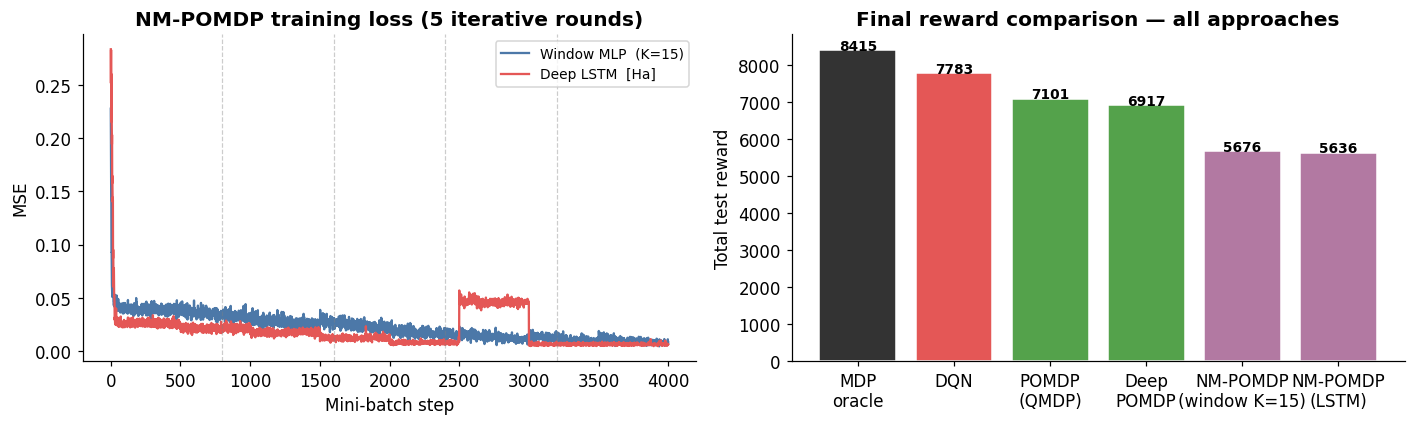

FINAL RESULTS SUMMARY
Dataset : Sleep-EDF, 25 subjects, 46 688 epochs
Features: 126-dim Welch PSD (6ch x 21) -> 30-dim PCA
Train   : 11,160 epochs (balanced, cap=N1 x 2)
Test    : 9,213 epochs (natural distribution)

  MDP oracle                  :   8415.4  (100.0% of oracle)
  DQN                         :   7782.7  (92.5% of oracle)
  POMDP (QMDP)                :   7101.4  (84.4% of oracle)
  Deep POMDP                  :   6917.4  (82.2% of oracle)
  NM-POMDP (window K=15)      :   5675.6  (67.4% of oracle)
  NM-POMDP (LSTM)             :   5636.4  (67.0% of oracle)
POMDP artefacts saved.


In [32]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(nm_loss,   label=f'Window MLP  (K={K})', color='#4c78a8', lw=1.5)
axes[0].plot(lstm_loss, label='Deep LSTM  [Ha]',       color='#e45756', lw=1.5)
# mark training rounds
for boundary in [len(nm_loss)//5*i for i in range(1,5)]:
    axes[0].axvline(boundary, color='gray', ls='--', lw=0.8, alpha=0.4)
axes[0].set_title('NM-POMDP training loss (5 iterative rounds)', fontweight='bold')
axes[0].set_xlabel('Mini-batch step'); axes[0].set_ylabel('MSE')
axes[0].legend(fontsize=9)

methods_short = ['MDP\noracle','DQN','POMDP\n(QMDP)','Deep\nPOMDP',
                  f'NM-POMDP\n(window K={K})','NM-POMDP\n(LSTM)']
rews = [r_mdp_te, dqn_rew, pomdp_rew, dp_rew, nm_rew, lstm_rew]
cols = ['#333','#e45756','#54a24b','#54a24b','#b279a2','#b279a2']
bars = axes[1].bar(methods_short, rews, color=cols, edgecolor='white')
for b, v in zip(bars, rews):
    axes[1].text(b.get_x()+b.get_width()/2, v+5, f'{v:.0f}',
                  ha='center', fontsize=9, fontweight='bold')
axes[1].set_title('Final reward comparison — all approaches', fontweight='bold')
axes[1].set_ylabel('Total test reward')
plt.tight_layout()
plt.savefig('fig9_nm.png', bbox_inches='tight'); plt.show()

print('=' * 62)
print('FINAL RESULTS SUMMARY')
print('=' * 62)
print(f'Dataset : Sleep-EDF, 25 subjects, 46 688 epochs')
print(f'Features: 126-dim Welch PSD (6ch x 21) -> 30-dim PCA')
print(f'Train   : {len(y_tr):,} epochs (balanced, cap=N1 x 2)')
print(f'Test    : {len(y_te):,} epochs (natural distribution)')
print()
# Fixed: use .replace('\n', ' ') not .replace('\\n', ' ')
labels_clean = [m.replace('\n', ' ') for m in methods_short]
for nm, rw in zip(labels_clean, rews):
    print(f'  {nm:<28}: {rw:8.1f}  ({rw/r_mdp_te*100:.1f}% of oracle)')

np.save('nmpomdp_rew.npy', np.array(nm_rew))
np.save('lstm_rew.npy', np.array(lstm_rew))
print('POMDP artefacts saved.')